# 03. Baselines

Simple models on the same windows and the same chronological split as notebook 02, so the LSTM in `04` has honest
numbers to beat. Everything is fit on the training period only. Validation picks hyperparameters, and the test period
is scored once.

Two things are predicted for each ticker's next trading day:

1. **Next close price**, built from a predicted **log return**: `Close * exp(return)`. Return metrics come first,
   then the same forecasts scored as prices.
2. **Next-day volatility**, measured as `log(High / Low)`.

For returns the reference is "predict zero" (tomorrow's close equals today's). For volatility the reference is a
trailing average of recent ranges. Each score is expressed relative to its reference, with a 95% interval clustered by
day because tickers move together and treating 50k samples as independent would overstate certainty.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import Markdown, display
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from formative_1 import stock_data as sd

SEED = 42
clean = pl.read_parquet("../data/processed/clean.parquet")
X, y, day, ticker, close, y_vol = sd.make_windows(
    sd.add_features(clean), extras=("Ticker", "Close", "target_vol")
)
train, val, test = sd.split_masks(day)
y_std = float(y[train].std())
vol_std = float(y_vol[train].std())
T, names = sd.window_summary(X)
print(f"{len(y):,} samples, {T.shape[1]} tabular features; train {train.sum():,} / val {val.sum():,} / test {test.sum():,}")
warnings.filterwarnings("ignore", category=RuntimeWarning)  # corr of constant predictions

299,770 samples, 28 tabular features; train 204,210 / val 43,031 / test 52,529


## Scoring helpers

In [2]:
def day_clustered_delta(y_true, pred, days, mask):
    """Mean of (zero-model squared error - model squared error), with a 95% CI clustered by day."""
    gain = (y_true[mask] ** 2) - (y_true[mask] - pred[mask]) ** 2
    per_day = pl.DataFrame({"day": days[mask], "gain": gain}).group_by("day").agg(pl.col("gain").mean())["gain"].to_numpy()
    se = per_day.std(ddof=1) / np.sqrt(len(per_day))
    return per_day.mean(), 1.96 * se


def score(name, pred, rows):
    for split, mask in [("val", val), ("test", test)]:
        yt, yp = y[mask], pred[mask]
        mse = float(np.mean((yt - yp) ** 2))
        gain, ci = day_clustered_delta(y, pred, day, mask)
        rows.append(
            {
                "model": name,
                "split": split,
                "mse": mse,
                "r2_vs_zero": 1 - mse / float(np.mean(yt**2)),
                "direction_acc": float(np.mean(np.sign(yt) == np.sign(yp))) if yp.any() else float("nan"),
                "corr": float(np.corrcoef(yt, yp)[0, 1]) if yp.std() > 0 else float("nan"),
                "mse_gain_vs_zero": gain,
                "ci95": ci,
            }
        )


rows = []
preds = {}

## Naive baselines

- **Zero**: predict no change.
- **Train mean**: predict the average training return every day (a tiny positive drift).
- **Yesterday's return**: predict that the next return equals today's. This is a momentum rule, and it usually loses on MSE because it doubles the noise.

In [3]:
preds["zero return"] = np.zeros_like(y)
preds["train-mean return"] = np.full_like(y, y[train].mean())
preds["yesterday's return"] = X[:, -1, sd.FEATURES.index("log_ret")]
for k in ("zero return", "train-mean return", "yesterday's return"):
    score(k, preds[k], rows)
pl.DataFrame(rows)

model,split,mse,r2_vs_zero,direction_acc,corr,mse_gain_vs_zero,ci95
str,str,f64,f64,f64,f64,f64,f64
"""zero return""","""val""",0.000697,0.0,NaN,NaN,0.0,0.0
"""zero return""","""test""",0.000774,0.0,NaN,NaN,0.0,0.0
"""train-mean return""","""val""",0.000697,0.000869,0.528619,NaN,6.2175e-7,8.8652e-7
"""train-mean return""","""test""",0.000774,-0.00028,0.50494,NaN,-2.1672e-7,8.4868e-7
"""yesterday's return""","""val""",0.001476,-1.115987,0.484302,-0.059162,-0.000775,0.000149
"""yesterday's return""","""test""",0.001562,-1.017481,0.496792,-0.0087,-0.000787,0.000086


## Ridge regression

Linear on the 28 tabular features, standardised with training statistics. The penalty is chosen on validation MSE.

In [4]:
ridge_val = {}
for alpha in [1, 10, 100, 1000, 10000]:
    m = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(T[train], y[train] / y_std)
    ridge_val[alpha] = float(np.mean((m.predict(T[val]) * y_std - y[val]) ** 2))
best_alpha = min(ridge_val, key=ridge_val.get)
display(Markdown(f"Validation MSE by alpha: {ridge_val}. Chosen alpha: **{best_alpha}**."))
ridge = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha)).fit(T[train], y[train] / y_std)
preds["ridge"] = ridge.predict(T) * y_std
score("ridge", preds["ridge"], rows)

Validation MSE by alpha: {1: 0.0007000389159657061, 10: 0.0007000384503044188, 100: 0.0007000335026532412, 1000: 0.0006999874021857977, 10000: 0.0006996655138209462}. Chosen alpha: **10000**.

## Gradient boosting

Histogram gradient boosting on the same features. A small grid is scored on validation. Leaves are required to hold
many samples because the target is mostly noise and small leaves would just fit it.

In [5]:
grid = [(d, it) for d in (3, 6) for it in (100, 300)]
hgb_val, hgb_models = {}, {}
for depth, iters in grid:
    t0 = time.time()
    m = HistGradientBoostingRegressor(
        max_depth=depth, max_iter=iters, learning_rate=0.05, min_samples_leaf=500,
        l2_regularization=1.0, random_state=SEED,
    ).fit(T[train], y[train] / y_std)
    hgb_models[(depth, iters)] = m
    hgb_val[(depth, iters)] = float(np.mean((m.predict(T[val]) * y_std - y[val]) ** 2))
    print(f"depth={depth} iters={iters}: val mse {hgb_val[(depth, iters)]:.6f} ({time.time() - t0:.0f}s)")
best_hgb = min(hgb_val, key=hgb_val.get)
display(Markdown(f"Chosen (max_depth, max_iter): **{best_hgb}**."))
preds["gradient boosting"] = hgb_models[best_hgb].predict(T) * y_std
score("gradient boosting", preds["gradient boosting"], rows)

depth=3 iters=100: val mse 0.000716 (1s)


depth=3 iters=300: val mse 0.000723 (2s)


depth=6 iters=100: val mse 0.000722 (1s)


depth=6 iters=300: val mse 0.000732 (3s)


Chosen (max_depth, max_iter): **(3, 100)**.

## Random Forest

The same family as the archived AAPL model, now on scale-free features and all tickers. Each tree sees a 30% subsample and
leaves hold at least 200 samples, so it trains quickly and does not memorise noise.

In [6]:
t0 = time.time()
rf = RandomForestRegressor(
    n_estimators=150, max_samples=0.3, min_samples_leaf=200, max_features=0.5, n_jobs=-1, random_state=SEED
).fit(T[train], y[train] / y_std)
print(f"trained in {time.time() - t0:.0f}s")
preds["random forest"] = rf.predict(T) * y_std
score("random forest", preds["random forest"], rows)

trained in 99s


## Comparison

In [7]:
results = pl.DataFrame(rows)
fmt = results.with_columns(
    pl.col("mse", "mse_gain_vs_zero", "ci95").round(7), pl.col("r2_vs_zero", "direction_acc", "corr").round(4)
)
display(Markdown("**Test period (2022 onward)**"))
display(fmt.filter(pl.col("split") == "test").drop("split").sort("mse"))
display(Markdown("**Validation period (2019 to 2021)**"))
display(fmt.filter(pl.col("split") == "val").drop("split").sort("mse"))
up = {s: float(np.mean(y[m] > 0)) for s, m in [("val", val), ("test", test)]}
display(Markdown(f"Always guessing \"up\": direction accuracy {up['val']:.3f} (val), {up['test']:.3f} (test)."))

**Test period (2022 onward)**

model,mse,r2_vs_zero,direction_acc,corr,mse_gain_vs_zero,ci95
str,f64,f64,f64,f64,f64,f64
"""zero return""",0.0007742,0.0,NaN,NaN,0.0,0.0
"""random forest""",0.0007742,-0.0,0.5135,0.0401,-0.0,0.0000044
"""train-mean return""",0.0007744,-0.0003,0.5049,NaN,-2.0000e-7,0.0000008
"""ridge""",0.0007746,-0.0006,0.5024,0.0197,-4.0000e-7,0.0000029
"""gradient boosting""",0.0007783,-0.0054,0.5123,0.0196,-0.000004,0.0000063
"""yesterday's return""",0.0015619,-1.0175,0.4968,-0.0087,-0.000787,0.0000865


**Validation period (2019 to 2021)**

model,mse,r2_vs_zero,direction_acc,corr,mse_gain_vs_zero,ci95
str,f64,f64,f64,f64,f64,f64
"""train-mean return""",0.0006967,0.0009,0.5286,NaN,0.0000006,0.0000009
"""zero return""",0.0006973,0.0,NaN,NaN,0.0,0.0
"""ridge""",0.0006997,-0.0033,0.5159,-0.0239,-0.000002,0.0000053
"""random forest""",0.0007064,-0.013,0.5061,-0.051,-0.000009,0.0000098
"""gradient boosting""",0.0007159,-0.0266,0.5225,-0.0895,-0.000018,0.0000211
"""yesterday's return""",0.0014756,-1.116,0.4843,-0.0592,-0.000775,0.0001493


Always guessing "up": direction accuracy 0.529 (val), 0.505 (test).

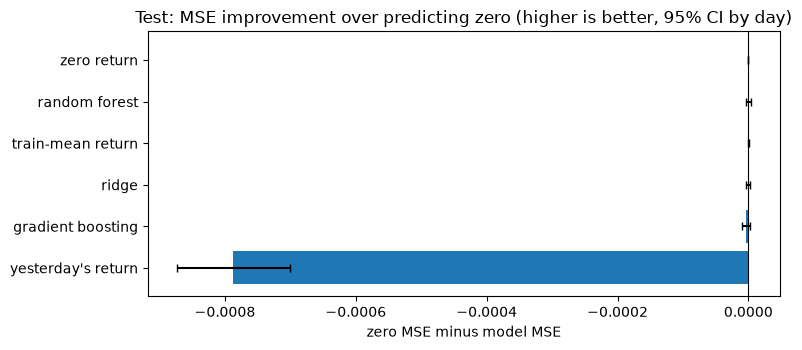

In [8]:
test_rows = results.filter(pl.col("split") == "test").sort("mse_gain_vs_zero")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(test_rows["model"], test_rows["mse_gain_vs_zero"], xerr=test_rows["ci95"], capsize=3)
ax.axvline(0, c="black", lw=0.8)
ax.set(title="Test: MSE improvement over predicting zero (higher is better, 95% CI by day)", xlabel="zero MSE minus model MSE")
fig.tight_layout()
plt.show()

## Next close price

The return forecasts above converted to prices with `Close * exp(return)`. Dollar errors are dominated by expensive stocks,
so the table uses the mean absolute percentage error (MAPE) of the predicted close. The zero-return model is exactly
"tomorrow's close = today's close".

In [9]:
actual_close = close * np.exp(y)
price_rows = []
for name, p in preds.items():
    if name == "yesterday's return":
        continue
    pred_close = close * np.exp(p)
    row = {"model": name}
    for split, mask in [("val", val), ("test", test)]:
        row[f"{split}_MAPE_%"] = float(np.mean(np.abs(pred_close[mask] - actual_close[mask]) / actual_close[mask]) * 100)
    price_rows.append(row)
price_table = pl.DataFrame(price_rows).sort("test_MAPE_%")
price_table.with_columns(pl.col("val_MAPE_%", "test_MAPE_%").round(4))

model,val_MAPE_%,test_MAPE_%
str,f64,f64
"""zero return""",1.6709,1.7845
"""train-mean return""",1.6695,1.7852
"""ridge""",1.6702,1.7865
"""random forest""",1.6781,1.7874
"""gradient boosting""",1.6811,1.793


The differences are tiny because a one-day return is small next to the price level. Any model that stays close to
"no change" gets a good MAPE, so a low price error alone does not show skill. The return metrics above are the real test.

A bar whose interval crosses zero is not distinguishable from predicting no change.

## Which features does the forest use?

In [10]:
imp = pl.DataFrame({"feature": names, "importance": rf.feature_importances_}).sort("importance", descending=True)
imp.head(10)

feature,importance
str,f64
"""mkt_ret_lag3""",0.14042
"""mkt_ret_lag4""",0.104307
"""mkt_ret_lag1""",0.093038
"""mkt_ret_lag2""",0.073303
"""mkt_ret_lag0""",0.072235
"""ret_mean_10""",0.040321
"""hl_mean_30""",0.036488
"""hl_range_lag0""",0.03375
"""ret_mean_5""",0.029907


## Per-ticker view

The best model by validation MSE, scored on each ticker's test samples. Tickers with few test samples are noisy, so the count is shown.

In [11]:
learned = ["ridge", "gradient boosting", "random forest"]  # constant rules carry no per-ticker information
best_name = results.filter((pl.col("split") == "val") & pl.col("model").is_in(learned)).sort("mse")["model"][0]
p = preds[best_name]
per_ticker = (
    pl.DataFrame({"ticker": ticker[test], "y": y[test], "p": p[test]})
    .group_by("ticker")
    .agg(
        n=pl.len(),
        mse=((pl.col("y") - pl.col("p")) ** 2).mean(),
        zero_mse=(pl.col("y") ** 2).mean(),
        direction_acc=(pl.col("y").sign() == pl.col("p").sign()).mean(),
    )
    .with_columns(r2_vs_zero=1 - pl.col("mse") / pl.col("zero_mse"))
    .sort("r2_vs_zero", descending=True)
)
beat = per_ticker.filter(pl.col("r2_vs_zero") > 0).height
display(Markdown(f"**{best_name}** beats the zero baseline on **{beat} of {per_ticker.height}** tickers in the test period."))
per_ticker.select("ticker", "n", pl.col("r2_vs_zero").round(4), pl.col("direction_acc").round(3))

**ridge** beats the zero baseline on **23 of 61** tickers in the test period.

ticker,n,r2_vs_zero,direction_acc
str,u32,f32,f64
"""PINS""",872,0.0051,0.532
"""FDX""",872,0.0046,0.529
"""AEO""",872,0.0042,0.499
"""PMMAF""",602,0.0041,0.485
"""BAMXF""",579,0.0035,0.425
…,…,…,…
"""JNJ""",872,-0.0052,0.495
"""LUV""",872,-0.0063,0.489
"""ADBE""",872,-0.0064,0.47


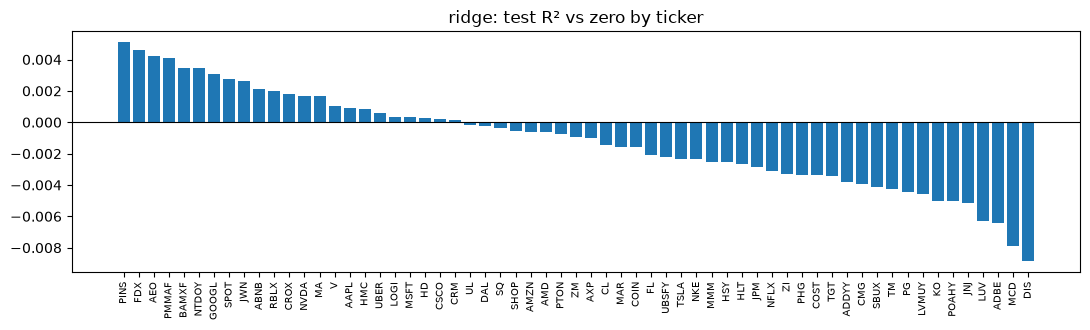

In [12]:
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(per_ticker["ticker"], per_ticker["r2_vs_zero"])
ax.axhline(0, c="black", lw=0.8)
ax.set(title=f"{best_name}: test R² vs zero by ticker")
ax.tick_params(axis="x", rotation=90, labelsize=7)
fig.tight_layout()
plt.show()

# Volatility baselines

The target is tomorrow's `log(High / Low)`. The reference forecasts use only the window:
- **today's range** (`hl_range_lag0`)
- **5-day mean range** and **30-day mean range** (`hl_mean_5`, `hl_mean_30`)

Learned models use the same 28 tabular features as before. The score is **R² vs the best trailing average**
(chosen on validation) = 1 - MSE / MSE of that reference. Positive means the model forecasts volatility better than a
trailing mean.

In [13]:
def vol_score(name, pred, ref_pred, rows):
    for split, mask in [("val", val), ("test", test)]:
        yt, yp = y_vol[mask], pred[mask]
        mse = float(np.mean((yt - yp) ** 2))
        ref_mse = float(np.mean((yt - ref_pred[mask]) ** 2))
        gain = (yt - ref_pred[mask]) ** 2 - (yt - yp) ** 2
        per_day = pl.DataFrame({"day": day[mask], "g": gain}).group_by("day").agg(pl.col("g").mean())["g"].to_numpy()
        rows.append(
            {
                "model": name,
                "split": split,
                "mse": mse,
                "r2": 1 - mse / float(np.var(yt)),
                "r2_vs_reference": 1 - mse / ref_mse,
                "corr": float(np.corrcoef(yt, yp)[0, 1]),
                "mse_gain": float(per_day.mean()),
                "ci95": float(1.96 * per_day.std(ddof=1) / np.sqrt(len(per_day))),
            }
        )


col = {n_: k for k, n_ in enumerate(names)}
vol_preds = {
    "overall mean": np.full_like(y_vol, y_vol[train].mean()),
    "today's range": T[:, col["hl_range_lag0"]],
    "5-day mean range": T[:, col["hl_mean_5"]],
    "30-day mean range": T[:, col["hl_mean_30"]],
}
simple = {k: float(np.mean((y_vol[val] - v[val]) ** 2)) for k, v in vol_preds.items()}
ref_name = min((k for k in simple if k != "overall mean"), key=simple.get)
display(Markdown(f"Validation MSE of the simple forecasts: {simple}. Reference (best trailing average): **{ref_name}**."))
ref = vol_preds[ref_name]

Validation MSE of the simple forecasts: {'overall mean': 0.0005902218582139534, "today's range": 0.0004594859396325772, '5-day mean range': 0.0003405977564155743, '30-day mean range': 0.00038680298166020636}. Reference (best trailing average): **5-day mean range**.

## Ridge, gradient boosting and Random Forest for volatility

Same recipe as for returns. Because volatility has real structure, the grid includes deeper trees and smaller leaves.

In [14]:
vol_val, vol_models = {}, {}
ridge_v = {}
for alpha in [1, 10, 100, 1000]:
    m = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(T[train], y_vol[train] / vol_std)
    ridge_v[alpha] = float(np.mean((m.predict(T[val]) * vol_std - y_vol[val]) ** 2))
alpha_v = min(ridge_v, key=ridge_v.get)
vol_preds["ridge"] = make_pipeline(StandardScaler(), Ridge(alpha=alpha_v)).fit(T[train], y_vol[train] / vol_std).predict(T) * vol_std
display(Markdown(f"Ridge validation MSE by alpha: {ridge_v}. Chosen alpha: **{alpha_v}**."))

hgb_v = {}
for depth, iters, leaf in [(3, 200, 200), (6, 200, 200), (6, 400, 100), (8, 400, 100)]:
    m = HistGradientBoostingRegressor(
        max_depth=depth, max_iter=iters, learning_rate=0.05, min_samples_leaf=leaf, l2_regularization=1.0, random_state=SEED
    ).fit(T[train], y_vol[train] / vol_std)
    hgb_v[(depth, iters, leaf)] = (m, float(np.mean((m.predict(T[val]) * vol_std - y_vol[val]) ** 2)))
    print(f"depth={depth} iters={iters} leaf={leaf}: val mse {hgb_v[(depth, iters, leaf)][1]:.3e}")
best_v = min(hgb_v, key=lambda k: hgb_v[k][1])
display(Markdown(f"Chosen gradient boosting (max_depth, max_iter, min_samples_leaf): **{best_v}**."))
vol_preds["gradient boosting"] = hgb_v[best_v][0].predict(T) * vol_std

Ridge validation MSE by alpha: {1: 0.00030220618562783603, 10: 0.0003022047486178357, 100: 0.00030219064575488596, 1000: 0.00030207566415224016}. Chosen alpha: **1000**.

depth=3 iters=200 leaf=200: val mse 2.948e-04


depth=6 iters=200 leaf=200: val mse 2.940e-04


depth=6 iters=400 leaf=100: val mse 2.946e-04


depth=8 iters=400 leaf=100: val mse 2.946e-04


Chosen gradient boosting (max_depth, max_iter, min_samples_leaf): **(6, 200, 200)**.

In [15]:
t0 = time.time()
rf_v = RandomForestRegressor(
    n_estimators=150, max_samples=0.3, min_samples_leaf=100, max_features=0.5, n_jobs=-1, random_state=SEED
).fit(T[train], y_vol[train] / vol_std)
print(f"trained in {time.time() - t0:.0f}s")
vol_preds["random forest"] = rf_v.predict(T) * vol_std

trained in 34s


### Volatility comparison

In [16]:
vol_rows = []
for k, p in vol_preds.items():
    vol_score(k, p, ref, vol_rows)
vol_results = pl.DataFrame(vol_rows)
fmt = vol_results.with_columns(pl.col("mse", "mse_gain", "ci95").round(9), pl.col("r2", "r2_vs_reference", "corr").round(4))
display(Markdown(f"**Test period (2022 onward).** Reference: {ref_name}."))
display(fmt.filter(pl.col("split") == "test").drop("split").sort("mse"))
display(Markdown("**Validation period (2019 to 2021)**"))
display(fmt.filter(pl.col("split") == "val").drop("split").sort("mse"))

**Test period (2022 onward).** Reference: 5-day mean range.

model,mse,r2,r2_vs_reference,corr,mse_gain,ci95
str,f64,f64,f64,f64,f64,f64
"""gradient boosting""",0.000191,0.5737,0.1368,0.7577,0.00003,0.000011
"""ridge""",0.000192,0.5698,0.1289,0.7548,0.000028,0.000008
"""random forest""",0.000193,0.5683,0.1259,0.7539,0.000028,0.000007
"""30-day mean range""",0.000218,0.5117,0.0115,0.7167,0.000003,0.000012
"""5-day mean range""",0.000221,0.5061,0.0,0.7207,0.0,0.0
"""today's range""",0.000309,0.3099,-0.3973,0.6549,-0.000088,0.00002
"""overall mean""",0.000454,-0.0142,-1.0534,0.0,-0.000232,0.000026


**Validation period (2019 to 2021)**

model,mse,r2,r2_vs_reference,corr,mse_gain,ci95
str,f64,f64,f64,f64,f64,f64
"""gradient boosting""",0.000294,0.501,0.1369,0.7083,0.000048,0.000024
"""random forest""",0.000301,0.4887,0.1156,0.6997,0.000041,0.000024
"""ridge""",0.000302,0.4872,0.1131,0.6982,0.00004,0.000022
"""5-day mean range""",0.000341,0.4218,0.0,0.6652,0.0,0.0
"""30-day mean range""",0.000387,0.3434,-0.1357,0.5935,-0.000045,0.000042
"""today's range""",0.000459,0.22,-0.3491,0.6101,-0.000123,0.000175
"""overall mean""",0.00059,-0.0019,-0.7329,NaN,-0.000247,0.000066


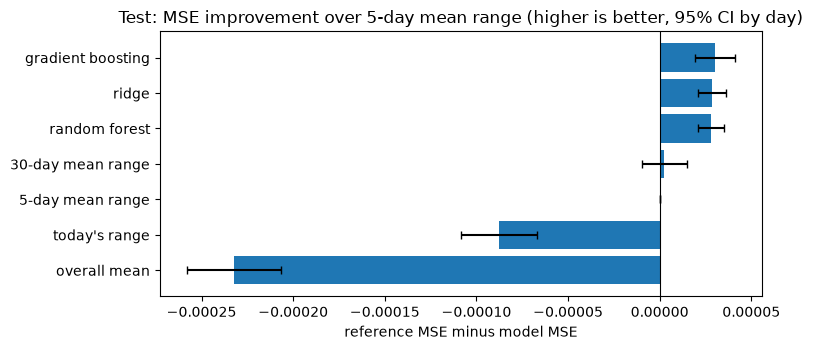

In [17]:
test_v = vol_results.filter(pl.col("split") == "test").sort("mse_gain")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(test_v["model"], test_v["mse_gain"], xerr=test_v["ci95"], capsize=3)
ax.axvline(0, c="black", lw=0.8)
ax.set(title=f"Test: MSE improvement over {ref_name} (higher is better, 95% CI by day)", xlabel="reference MSE minus model MSE")
fig.tight_layout()
plt.show()

### Volatility per ticker

In [18]:
learned_v = ["ridge", "gradient boosting", "random forest"]
best_v_name = vol_results.filter((pl.col("split") == "val") & pl.col("model").is_in(learned_v)).sort("mse")["model"][0]
pv = vol_preds[best_v_name]
vol_ticker = (
    pl.DataFrame({"ticker": ticker[test], "y": y_vol[test], "p": pv[test], "r": ref[test]})
    .group_by("ticker")
    .agg(n=pl.len(), mse=((pl.col("y") - pl.col("p")) ** 2).mean(), ref_mse=((pl.col("y") - pl.col("r")) ** 2).mean())
    .with_columns(r2_vs_reference=1 - pl.col("mse") / pl.col("ref_mse"))
    .sort("r2_vs_reference", descending=True)
)
beat_v = vol_ticker.filter(pl.col("r2_vs_reference") > 0).height
display(Markdown(f"**{best_v_name}** beats the {ref_name} reference on **{beat_v} of {vol_ticker.height}** tickers in the test period."))
vol_ticker.select("ticker", "n", pl.col("r2_vs_reference").round(4))

**gradient boosting** beats the 5-day mean range reference on **61 of 61** tickers in the test period.

ticker,n,r2_vs_reference
str,u32,f64
"""AAPL""",872,0.2136
"""DIS""",872,0.209
"""FDX""",872,0.1995
"""DAL""",872,0.1982
"""LUV""",872,0.1939
…,…,…
"""CL""",872,0.0854
"""COIN""",872,0.0833
"""MCD""",872,0.0686


In [19]:
vol_significant = vol_results.filter(
    (pl.col("split") == "test") & pl.col("model").is_in(learned_v) & (pl.col("mse_gain") - pl.col("ci95") > 0)
)
display(Markdown(f"""
**Volatility takeaway.** Learned models that beat the {ref_name} reference with a day-clustered interval above 0 on the test period:
**{vol_significant.height} of {len(learned_v)}**. Best on validation: **{best_v_name}**, with test R² vs reference
{vol_results.filter((pl.col('split') == 'test') & (pl.col('model') == best_v_name))['r2_vs_reference'][0]:+.4f}.
"""))
vol_results.write_csv("../data/processed/baseline_vol_results.csv")


**Volatility takeaway.** Learned models that beat the 5-day mean range reference with a day-clustered interval above 0 on the test period:
**3 of 3**. Best on validation: **gradient boosting**, with test R² vs reference
+0.1368.


## Return takeaways

In [20]:
learned_test = results.filter((pl.col("split") == "test") & pl.col("model").is_in(learned))
significant = learned_test.filter(pl.col("mse_gain_vs_zero") - pl.col("ci95") > 0)
display(Markdown(f"""
- Learned models whose test improvement over zero is statistically distinguishable from 0: **{significant.height} of {learned_test.height}**.
- Best learned model on validation: **{best_name}**. Its test R² vs zero is
  {learned_test.filter(pl.col("model") == best_name)["r2_vs_zero"][0]:+.4f}.
- This is the bar for `04`: an LSTM only counts as better if its improvement over zero is positive and its day-clustered interval excludes 0.
"""))


- Learned models whose test improvement over zero is statistically distinguishable from 0: **0 of 3**.
- Best learned model on validation: **ridge**. Its test R² vs zero is
  -0.0006.
- This is the bar for `04`: an LSTM only counts as better if its improvement over zero is positive and its day-clustered interval excludes 0.


In [21]:
results.write_csv("../data/processed/baseline_results.csv")